# Student Performance Classification: PyTorch Deep Learning (Simple MLP)

A clean, beginner-friendly Deep Learning implementation using **PyTorch** for classifying student final grades (**A, B, C, D, F**).

### Workflow:
1. **Load & Preprocess Data** (Same preprocessing as Phase 2)
2. **PyTorch DataLoaders** (Batching & shuffling)
3. **Build Simple MLP** (`torch.nn.Module`)
4. **Train Model** (Cross-Entropy Loss + Adam Optimizer)
5. **Plot Learning Curves** (Loss & Accuracy)
6. **Evaluate on Test Data** (Accuracy, Classification Report, Confusion Matrix)
7. **Single Sample Prediction** (Live inference demo)
8. **Comparison with Phase 2 Models** (Classical ML vs Deep Learning)

## 1. Import Libraries & Set Device

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Set random seed for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Detect device (GPU if available, else CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 2. Load & Preprocess Dataset
We follow the exact same Phase 2 preprocessing:
- Drop `student_id`
- Encode categorical features and target (`final_grade`)
- 80/20 stratified train/test split
- Feature scaling with `StandardScaler`
- Convert to PyTorch tensors

In [2]:
# Load dataset
df = pd.read_csv('student_performance_dataset.csv')
print(f"Dataset shape: {df.shape}")

# Drop ID column
df_clean = df.drop(columns=['student_id'])

# Encode categorical features
categorical_cols = ['gender', 'parental_education', 'internet_access', 'extracurricular_activities', 'part_time_job']
for col in categorical_cols:
    df_clean[col] = LabelEncoder().fit_transform(df_clean[col])

# Encode target final_grade (A, B, C, D, F)
target_le = LabelEncoder()
df_clean['final_grade'] = target_le.fit_transform(df_clean['final_grade'])
class_names = list(target_le.classes_)

X = df_clean.drop(columns=['final_grade']).values
y = df_clean['final_grade'].values

print(f"Features: {X.shape[1]} | Target Classes: {class_names}")

# 80/20 Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Feature Scaling (Fit on Train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Dataset shape: (1000, 12)
Features: 10 | Target Classes: ['A', 'B', 'C', 'D', 'F']
Training samples: 800 | Testing samples: 200


## 3. Create PyTorch DataLoaders
We use mini-batches of size 32, shuffling training data.

In [3]:
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Batches per epoch: {len(train_loader)} (Batch size: {batch_size})")

Batches per epoch: 25 (Batch size: 32)


## 4. Build Simple Multi-Layer Perceptron (MLP)
Architecture:
- **Input Layer**: 10 features
- **Hidden Layer 1**: 64 neurons + ReLU activation
- **Hidden Layer 2**: 32 neurons + ReLU activation
- **Output Layer**: 5 classes (raw logits for A, B, C, D, F)

In [4]:
class SimpleStudentMLP(nn.Module):
    def __init__(self, input_dim=10, hidden1=64, hidden2=32, output_dim=5):
        super(SimpleStudentMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, output_dim)
        )
        
    def forward(self, x):
        return self.network(x)

# Instantiate model
model = SimpleStudentMLP(input_dim=10, hidden1=64, hidden2=32, output_dim=len(class_names)).to(device)
print(model)

SimpleStudentMLP(
  (network): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=5, bias=True)
  )
)


## 5. Train the Model
We use **Cross-Entropy Loss** and the **Adam Optimizer** (`lr=0.003`) over 30 epochs.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)

epochs = 30
history = {'loss': [], 'accuracy': []}

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        # 1. Clear gradients
        optimizer.zero_grad()
        # 2. Forward pass
        outputs = model(batch_x)
        # 3. Compute loss
        loss = criterion(outputs, batch_y)
        # 4. Backward pass (backpropagation)
        loss.backward()
        # 5. Update weights
        optimizer.step()
        
        running_loss += loss.item() * batch_x.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)
        
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    history['loss'].append(epoch_loss)
    history['accuracy'].append(epoch_acc)
    
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:2d}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc*100:.2f}%")

Epoch [ 1/30] - Loss: 1.3948 - Accuracy: 44.00%
Epoch [ 5/30] - Loss: 0.3457 - Accuracy: 89.00%
Epoch [10/30] - Loss: 0.1384 - Accuracy: 97.12%
Epoch [15/30] - Loss: 0.0797 - Accuracy: 97.75%
Epoch [20/30] - Loss: 0.0450 - Accuracy: 99.62%
Epoch [25/30] - Loss: 0.0278 - Accuracy: 99.75%
Epoch [30/30] - Loss: 0.0189 - Accuracy: 100.00%


## 6. Learning Curves
Visualizing loss reduction and accuracy improvement over epochs.

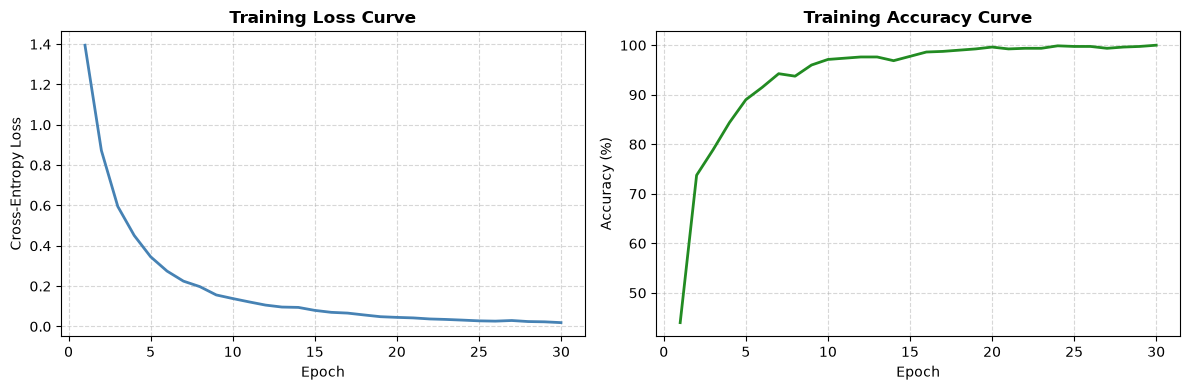

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Loss curve
ax1.plot(range(1, epochs + 1), history['loss'], color='steelblue', linewidth=2)
ax1.set_title("Training Loss Curve", fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, linestyle='--', alpha=0.5)

# Accuracy curve
ax2.plot(range(1, epochs + 1), [acc * 100 for acc in history['accuracy']], color='forestgreen', linewidth=2)
ax2.set_title("Training Accuracy Curve", fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 7. Model Evaluation on Test Set
Evaluate test accuracy, classification report, and confusion matrix on the unseen test set.

Test Accuracy: 91.00%
Test F1-Score: 0.9052

Classification Report:
              precision    recall  f1-score   support

           A       0.92      0.98      0.95        57
           B       0.90      0.92      0.91        71
           C       0.96      0.85      0.90        52
           D       0.81      0.94      0.87        18
           F       0.00      0.00      0.00         2

    accuracy                           0.91       200
   macro avg       0.72      0.74      0.73       200
weighted avg       0.90      0.91      0.91       200



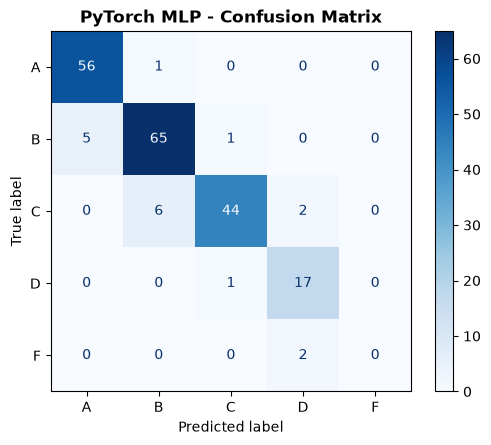

In [7]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        outputs = model(batch_x)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch_y.cpu().numpy())

test_acc = accuracy_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test F1-Score: {test_f1:.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title("PyTorch MLP - Confusion Matrix", fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Single Student Prediction Example
Demonstrating live inference on a single student sample.

In [8]:
sample_idx = 0
sample_input = X_test_tensor[sample_idx:sample_idx+1].to(device)
actual_grade = class_names[y_test_tensor[sample_idx].item()]

model.eval()
with torch.no_grad():
    logits = model(sample_input)
    probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
    pred_idx = torch.argmax(logits, dim=1).item()
    pred_grade = class_names[pred_idx]

print(f"Actual Grade    : {actual_grade}")
print(f"Predicted Grade : {pred_grade}")
print(f"Match           : {'✓ CORRECT' if actual_grade == pred_grade else '✗ INCORRECT'}")
print("\nClass Probabilities:")
for grade, prob in zip(class_names, probs):
    print(f"  Grade {grade}: {prob*100:5.2f}% {'█' * int(prob * 25)}")

Actual Grade    : A
Predicted Grade : A
Match           : ✓ CORRECT

Class Probabilities:
  Grade A: 100.00% █████████████████████████
  Grade B:  0.00% 
  Grade C:  0.00% 
  Grade D:  0.00% 
  Grade F:  0.00% 


## 9. Comparison with Phase 2 Classical ML Models
Comparing our PyTorch MLP directly against the 5 Phase 2 models on the exact same test set.


=== Model Comparison Table ===


,Model,Type,Accuracy (%),F1-Score
Rank,,,,
1,Decision Tree,Machine Learning,99.5,0.9954
2,Random Forest,Machine Learning,99.0,0.9853
3,Logistic Regression,Machine Learning,94.5,0.9400
4,PyTorch MLP,Deep Learning,91.0,0.9052
5,SVM,Machine Learning,88.0,0.8759
6,KNN,Machine Learning,77.0,0.7647


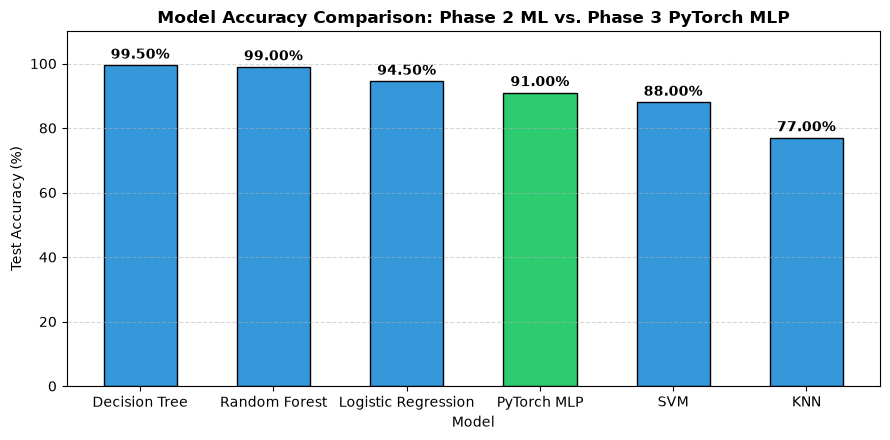

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

phase2_models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_split=10, min_samples_leaf=5, random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, min_samples_leaf=3, random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0, random_state=SEED),
    'SVM': SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED),
    'KNN': KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski')
}

results = []
for name, clf in phase2_models.items():
    clf.fit(X_train_scaled, y_train)
    preds = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='weighted')
    results.append({'Model': name, 'Type': 'Machine Learning', 'Accuracy (%)': round(acc * 100, 2), 'F1-Score': round(f1, 4)})

results.append({'Model': 'PyTorch MLP', 'Type': 'Deep Learning', 'Accuracy (%)': round(test_acc * 100, 2), 'F1-Score': round(test_f1, 4)})

comparison_df = pd.DataFrame(results).sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)
comparison_df.index = comparison_df.index + 1
comparison_df.index.name = 'Rank'

print("\n=== Model Comparison Table ===")
display(comparison_df)

# Bar chart
plt.figure(figsize=(9, 4.5))
colors = ['#2ecc71' if t == 'Deep Learning' else '#3498db' for t in comparison_df['Type']]
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'], color=colors, edgecolor='black', width=0.55)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., h + 1.0, f"{h:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.title("Model Accuracy Comparison: Phase 2 ML vs. Phase 3 PyTorch MLP", fontweight='bold')
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()